# Detect or Discard: error detection with spacetime codes, as a game

**Qiskit Fall Fest 2026 Hackathon, Advanced Track.**
This notebook contains the physics behind the game. It follows the six required steps of the brief
and reproduces every number used in the game and the report.

| Brief step | Section |
|---|---|
| 1. Build the payloads (Clifford + T-doped family) | §1 |
| 2. Fix the reference and the fidelity measure | §2 |
| 3. Add checks with qiskit-paulice | §3 |
| 4. Run under noise | §4 |
| 5. Measure | §5 |
| 6. Compare, find the best trade-off | §6 – §8 |

The game itself is in `game/app.py` (`streamlit run game/app.py`). It reads the same numbers.

**Reproducibility.** Everything is seeded. Section 5 recomputes live (about a minute); the large
sweeps in §6 are read from `results/*.csv`, written by `python src/run_experiments.py`.

In [1]:
import sys, platform
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import qiskit, qiskit_aer, qiskit_paulice
from importlib.metadata import version
from spacetime import *
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
print("python", platform.python_version(), "| qiskit", qiskit.__version__,
      "| aer", qiskit_aer.__version__, "| qiskit-paulice", version("qiskit-paulice"))
RES = ROOT / "results"

python 3.13.2 | qiskit 2.5.2 | aer 0.17.2 | qiskit-paulice 0.2.1


## 1 · Payload circuits

**Design choice: an echo (mirror) circuit.** The payload encodes a bitstring, applies a random
Clifford circuit `C`, then its inverse `C†`. In the ideal case the output is *one known bitstring*.
That makes the fidelity sensitive to noise. (A random Clifford spreads its output uniformly over all
bitstrings, so a noisy and an ideal run look the same under a distribution fidelity; we tried it and
it gave F = 0.999 at 1% noise.)

* **Width** 6 data qubits. **Depth**: `C` has 5 brickwork layers, so the echo is 10 layers; 26 CNOTs.
* **T-doped family.** `t_count` T gates are inserted in the middle of `C`; the mirror half contains
  the matching T†. The circuit has `t_count` non-Clifford gates (`t_count` = 0, 2, 4, 8, ...) but its
  ideal output is *still* the same bitstring. So the **fidelity stays comparable across T counts**,
  and T gates act on the problem the way the brief describes: they limit which checks are valid.

In [2]:
rows = []
for t in (0, 2, 4, 8):
    lv = Level(t_count=t)
    ops = lv.payload.count_ops()
    rows.append(dict(t_count=t, width=lv.n, depth=lv.payload.depth(),
                     cnots=ops.get("cx", 0), T=ops.get("t", 0), Tdg=ops.get("tdg", 0),
                     ideal_outputs=len(lv.ideal), ideal_bitstring=max(lv.ideal, key=lv.ideal.get)))
pd.DataFrame(rows)

,t_count,width,depth,cnots,T,Tdg,ideal_outputs,ideal_bitstring
0,0,6,21,26,0,0,1,010101
1,2,6,23,26,1,1,1,010101
2,4,6,25,26,2,2,1,010101
3,8,6,25,26,4,4,1,010101


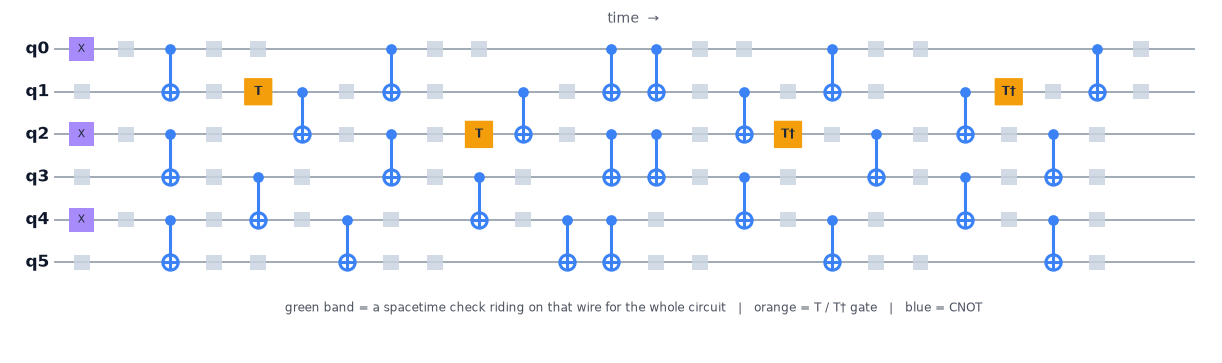

In [3]:
from board import draw_board
fig = draw_board(Level(t_count=4).payload, [], dark=False, figsize=(11, 3.2))
plt.show()

## 2 · Reference and fidelity measure

* **Clifford payload:** the ideal distribution is computed by **stabilizer simulation**
  (`StabilizerState(Clifford(circuit)).probabilities_dict()`).
* **T-doped payload:** by **statevector simulation** (`Statevector(circuit)`), fine for 6 qubits.
* **Fidelity:** the classical (Hellinger) fidelity `F = (Σ_x √(p(x) q(x)))²` between the measured
  distribution `q` over the data bits and the ideal `p`.
  *Justification:* the ideal output is a single bitstring, so `F` is the probability of getting it;
  the same formula also covers the T-doped case without changes. Post-selection compares only
  the kept shots. Uncertainty: bootstrap (multinomial resampling of the kept counts), 100 resamples.
* **Shots:** 20 000 per configuration. A post-selected fidelity is always reported with its
  kept-shot fraction.

In [4]:
lv = Level(t_count=4)
print("ideal (T-doped, statevector):", {k: round(v, 6) for k, v in lv.ideal.items()})
print("ideal (Clifford, stabilizer):", Level(t_count=0).ideal)

ideal (T-doped, statevector): {'010101': 1.0}
ideal (Clifford, stabilizer): {'010101': 1.0}


## 3 · Checks with qiskit-paulice

`add_pauli_checks(circuit, target_qubits, noise_model, ...)` returns one circuit per number of
checks: the bare circuit, then one check per target qubit, in order. The checks are chosen to minimise
a cost (the default, `gamma`, is the inverse of the fraction of noise left undetected, so *lower is
better*). It needs a **Clifford** circuit. Given the T-doped payload it raises an error, shown below.

In [5]:
lv0 = Level(t_count=0)
res = add_pauli_checks(with_measure(lv0.clifford), list(range(6)), paulice_noise(0.01, 0.005),
                       cost="gamma", seed=1)
pd.DataFrame([dict(checks=len(r.check_qubits), two_qubit_gates=sum(len(i.qubits) == 2 for i in r.circuit.data),
                   depth=r.circuit.depth(), qubits=r.circuit.num_qubits,
                   gamma=r.cost, support=r.check_support) for r in res])

,checks,two_qubit_gates,depth,qubits,gamma,support
0,0,26,23,6,1.781810,()
1,1,29,36,7,1.650099,"((0, 6),)"
2,2,33,50,8,1.391735,"((0, 6), (1, 2, 3, 4, 7))"
3,3,36,51,9,1.217738,"((0, 6), (1, 2, 3, 4, 7), (2, 8))"
4,4,39,54,10,1.131495,"((0, 6), (1, 2, 3, 4, 7), (2, 8), (3, 9))"
5,5,42,57,11,1.109052,"((0, 6), (1, 2, 3, 4, 7), (2, 8), (3, 9), (4, ..."
6,6,45,57,12,1.107202,"((0, 6), (1, 2, 3, 4, 7), (2, 8), (3, 9), (4, ..."


In [6]:
try:
    add_pauli_checks(with_measure(Level(t_count=4).payload), [0, 1], paulice_noise(), seed=1)
except Exception as e:
    print(type(e).__name__, "->", str(e)[:400])

AssertionError -> Gate set is: {'sx', 'cx', 'sdg', 't', 'sxdg', 'x', 's', 'tdg', 'h'}


### Hand-made checks for the T-doped circuits

A spacetime check is a pair of Paulis `(L, R)` with `U L U† = ±R`: apply controlled-`L` before the
payload, controlled-`R` after it, read the ancilla in the X basis. For a Clifford `U` every `L`
works. A **T gate** is diagonal, so it commutes with Z but turns X into `(X+Y)/√2`, which is not a
Pauli. A check is valid across a T gate only if its Pauli acts as **I or Z** there. We enumerate
all `4⁶` left Paulis, push each through the circuit (`propagate_pauli`), and keep those that never meet
X/Y at a T gate. Then each target wire gets the cheapest valid check that touches it, is independent of
the others, and **commutes** with them (anticommuting checks disturb each other even without noise;
we found this bug the hard way).

**Self-test:** with noise switched off, every check we build must flag zero shots. We verify this on all
256 (4 T-counts × 64 target subsets) configurations.

In [7]:
pool_sizes = {t: len(Level(t_count=t).pool) for t in (0, 2, 4, 8)}
print("valid left-Paulis (out of 4^6-1 = 4095):", pool_sizes)
v = pd.read_csv(RES / "validity_noiseless.csv")
print("noiseless self-test: configurations =", len(v), "| all shots kept:", bool((v.kept_noiseless == 1).all()),
      "| min noiseless fidelity:", round(v.fidelity_noiseless.min(), 4))

valid left-Paulis (out of 4^6-1 = 4095): {0: 4095, 2: 2047, 4: 1023, 8: 255}


noiseless self-test: configurations = 256 | all shots kept: True | min noiseless fidelity: 1.0


## 4 · Noise

The brief says to use the organizers' model; its example is `NoiseModel(gate_noise=0.01)`. We use
exactly that **for both paulice (to pick checks) and Aer (to simulate)**:

* every CNOT: a Pauli error with total probability `p2 = 1%`, spread uniformly over the 15 non-identity
  two-qubit Paulis (`depolarizing_error(p2·16/15, 2)` in Aer);
* every measurement flips with probability 0.5%;
* single-qubit gates (incl. T) are noiseless, as in paulice's own model.

> If the organizers publish a different model, change `P2_DEFAULT` / `PRO_DEFAULT` in `src/spacetime.py`
> and rerun `python src/run_experiments.py`.

All the controlled-Pauli gates of the checks are built from the *same noisy CNOT*, so checks pay for
their own gates.

## 5 · Measure (recomputed live)

For each configuration: fidelity without checks, post-selected fidelity, kept fraction and cost
(ancillas, two-qubit gates, depth). Targets are wires `0..k-1`.

In [8]:
def sweep(level, method=None, ks=range(7)):
    out = []
    for k in ks:
        r = level.evaluate(list(range(k)), method=method)
        out.append(dict(T=level.t_count, checks=r.n_checks, F_raw=r.fidelity_raw,
                        F_post=r.fidelity_post, F_err=r.fidelity_post_err, kept=r.kept,
                        efficiency=r.efficiency, ancillas=r.ancillas, cx=r.two_qubit_gates, depth=r.depth))
    return pd.DataFrame(out)

live0 = sweep(Level(t_count=0)); live0.round(4)

,T,checks,F_raw,F_post,F_err,kept,efficiency,ancillas,cx,depth
0,0,0,0.7714,0.7714,0.0029,1.0000,0.5951,0,26,22
1,0,1,0.7563,0.7980,0.0028,0.9296,0.5920,1,29,36
2,0,2,0.7367,0.8632,0.0023,0.8254,0.6150,2,33,48
3,0,3,0.7166,0.9124,0.0025,0.7538,0.6276,3,36,51
4,0,4,0.7031,0.9419,0.0020,0.7070,0.6273,4,39,54
5,0,5,0.6907,0.9488,0.0019,0.6779,0.6103,5,42,57
6,0,6,0.6792,0.9533,0.0017,0.6530,0.5934,6,45,57


In [9]:
live4 = sweep(Level(t_count=4)); live4.round(4)

,T,checks,F_raw,F_post,F_err,kept,efficiency,ancillas,cx,depth
0,4,0,0.7693,0.7693,0.0029,1.0000,0.5919,0,26,26
1,4,1,0.7660,0.7993,0.0029,0.9515,0.6078,1,27,29
2,4,2,0.7587,0.8200,0.0026,0.9020,0.6065,2,29,31
3,4,3,0.7577,0.8822,0.0025,0.8322,0.6477,3,30,31
4,4,4,0.7461,0.9064,0.0024,0.7849,0.6448,4,32,31
5,4,5,0.7427,0.9186,0.0027,0.7640,0.6446,5,33,31
6,4,6,0.7366,0.9290,0.0020,0.7455,0.6435,6,34,31


**Clifford vs T-doped, at equal check count.** (Prefix targets, hand-made checks for both so that
the machinery is identical.)

In [10]:
t = pd.read_csv(RES / "t_sweep.csv", dtype={"targets": str})
piv = t.pivot_table(index="checks", columns="t_count", values="fidelity_post")
piv.round(3)

t_count,0,2,4,6,8,10
checks,,,,,,
0,0.771,0.770,0.769,0.769,0.769,0.769
1,0.802,0.800,0.799,0.784,0.785,0.785
2,0.848,0.820,0.820,0.832,0.832,0.832
3,0.903,0.882,0.882,0.867,0.866,0.866
4,0.934,0.916,0.906,0.877,0.876,0.876
5,0.944,0.930,0.919,0.890,0.878,NaN
6,0.955,0.941,0.929,NaN,NaN,NaN


## 6 · Compare

### 6.1 Fidelity and kept fraction vs number of checks

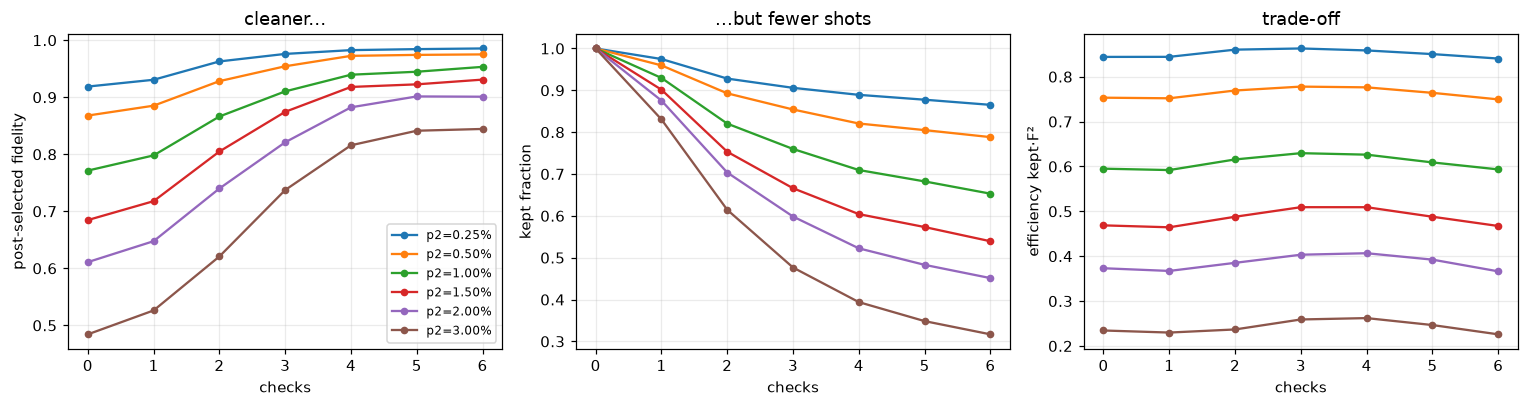

In [11]:
n = pd.read_csv(RES / "noise_sweep.csv", dtype={"targets": str})
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for p2, g in n.groupby("p2"):
    ax[0].plot(g.checks, g.fidelity_post, "-o", ms=4, label=f"p2={p2:.2%}")
    ax[1].plot(g.checks, g.kept, "-o", ms=4)
    ax[2].plot(g.checks, g.efficiency, "-o", ms=4)
ax[0].set(xlabel="checks", ylabel="post-selected fidelity", title="cleaner...")
ax[1].set(xlabel="checks", ylabel="kept fraction", title="...but fewer shots")
ax[2].set(xlabel="checks", ylabel="efficiency kept·F²", title="trade-off")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**Reading it.** Post-selected fidelity rises with every check and saturates; the kept fraction falls
steadily, because every check adds noisy CNOTs that flag extra shots. Their product has an interior
maximum: that is the best trade-off. The noisier the hardware, the more checks are worth it and the more
the optimum moves right. On quiet hardware it can be zero checks.

### 6.2 Depth

In [12]:
d = pd.read_csv(RES / "depth_sweep.csv", dtype={"targets": str})
base = d[d.checks == 0].set_index("depth")
best = d.loc[d.groupby("depth").efficiency.idxmax()].set_index("depth")
pd.DataFrame({"2q gates": base.two_qubit_gates, "F no checks": base.fidelity_post,
              "best #checks": best.checks, "F best": best.fidelity_post, "kept best": best.kept,
              "eff no checks": base.efficiency, "eff best": best.efficiency,
              "gain": best.efficiency / base.efficiency}).round(3)

,2q gates,F no checks,best #checks,F best,kept best,eff no checks,eff best,gain
depth,,,,,,,,
1,6,0.927,0,0.927,1.000,0.859,0.859,1.000
2,10,0.894,0,0.894,1.000,0.798,0.798,1.000
3,16,0.847,0,0.847,1.000,0.717,0.717,1.000
5,26,0.771,3,0.912,0.754,0.595,0.628,1.055
8,40,0.678,4,0.930,0.627,0.460,0.542,1.178
12,60,0.566,4,0.925,0.508,0.320,0.435,1.360


### 6.3 T count

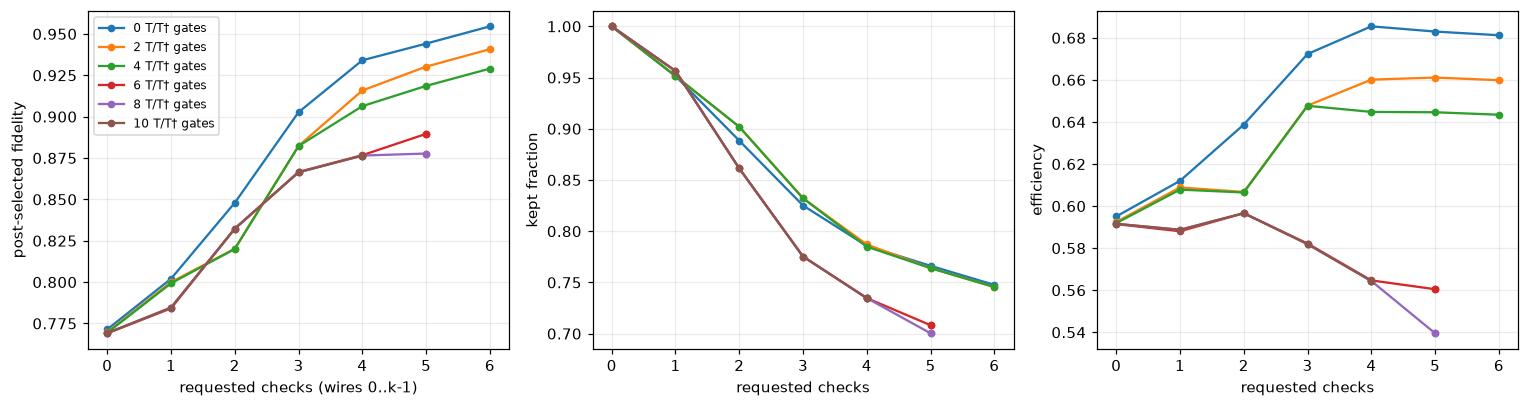

valid left Paulis in the pool: {0: 4095, 2: 2047, 4: 1023, 6: 511, 8: 255, 10: 127}


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for tc, g in t.groupby("t_count"):
    ax[0].plot(g.checks, g.fidelity_post, "-o", ms=4, label=f"{tc} T/T† gates")
    ax[1].plot(g.checks, g.kept, "-o", ms=4)
    ax[2].plot(g.checks, g.efficiency, "-o", ms=4)
ax[0].set(xlabel="requested checks (wires 0..k-1)", ylabel="post-selected fidelity")
ax[1].set(xlabel="requested checks", ylabel="kept fraction")
ax[2].set(xlabel="requested checks", ylabel="efficiency")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
print("valid left Paulis in the pool:", t.drop_duplicates("t_count")[["t_count", "pool"]].set_index("t_count").pool.to_dict())

**Reading it.** Without checks the fidelity is the same for every T count (the T gates are noiseless in
the model, and mirrored). With checks, more T gates means fewer valid checks (the pool of valid Paulis
halves with every extra T/T† pair), so the best reachable fidelity falls and the best number of checks
falls too.

### 6.4 Check location

          min  median    max  spread
checks                              
0       0.595   0.595  0.595   0.000
1       0.591   0.626  0.643   0.052
2       0.596   0.626  0.658   0.063
3       0.605   0.631  0.653   0.047
4       0.601   0.624  0.637   0.036
5       0.607   0.611  0.619   0.012
6       0.590   0.590  0.590   0.000


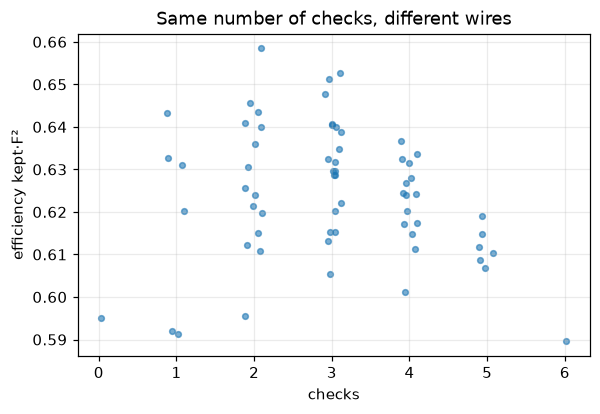

In [14]:
L = pd.read_csv(RES / "landscape.csv", dtype={"targets": str})
L0 = L[(L.t_count == 0) & (L.p2 == 0.01) & (L.depth == 5)]
g = L0.groupby("checks").efficiency.agg(["min", "median", "max"])
g["spread"] = g["max"] - g["min"]
print(g.round(3))
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.scatter(L0.checks + np.random.default_rng(0).uniform(-.12, .12, len(L0)), L0.efficiency, s=14, alpha=.6)
ax.set(xlabel="checks", ylabel="efficiency kept·F²", title="Same number of checks, different wires")
plt.show()

In [15]:
k3 = L0[L0.checks == 3].sort_values("efficiency")
print("worst 3-check placement:", k3.iloc[0][["targets", "fidelity_post", "kept", "efficiency"]].to_dict())
print("best  3-check placement:", k3.iloc[-1][["targets", "fidelity_post", "kept", "efficiency"]].to_dict())

worst 3-check placement: {'targets': '045', 'fidelity_post': 0.8655035882207375, 'kept': 0.8082, 'efficiency': 0.6054197599604059}
best  3-check placement: {'targets': '234', 'fidelity_post': 0.9158314058082756, 'kept': 0.7782, 'efficiency': 0.652713042919558}


## 7 · Best trade-off

In [16]:
rows = []
for (t_, p2, dep), g in L.groupby(["t_count", "p2", "depth"]):
    b = g.loc[g.efficiency.idxmax()]; z = g[g.targets == "-"].iloc[0]
    rows.append(dict(T=t_, p2=p2, depth=dep, best_wires=b.targets, checks=int(b.checks),
                     F_none=z.fidelity_post, F_best=b.fidelity_post, kept_best=b.kept,
                     eff_none=z.efficiency, eff_best=b.efficiency, gain=b.efficiency / z.efficiency))
best_tbl = pd.DataFrame(rows).round(3); best_tbl

,T,p2,depth,best_wires,checks,F_none,F_best,kept_best,eff_none,eff_best,gain
0,0,0.005,5,23,2,0.868,0.943,0.890,0.753,0.792,1.052
1,0,0.010,2,-,0,0.894,0.894,1.000,0.798,0.798,1.000
2,0,0.010,5,23,2,0.771,0.902,0.810,0.595,0.658,1.107
3,0,0.010,8,124,3,0.678,0.927,0.663,0.460,0.569,1.237
4,0,0.020,5,235,3,0.611,0.845,0.634,0.373,0.453,1.213
5,2,0.010,5,0235,4,0.770,0.933,0.785,0.592,0.683,1.153
6,4,0.010,5,024,3,0.769,0.910,0.818,0.592,0.677,1.143
7,8,0.010,5,24,2,0.769,0.861,0.860,0.592,0.638,1.079


## 8 · Reproducibility and statistical honesty

In [17]:
s = pd.read_csv(RES / "seed_repeat.csv", dtype={"targets": str})
s.groupby("targets")[["fidelity_post", "kept", "efficiency"]].agg(["mean", "std"]).round(4)

fidelity_post            kept         efficiency        
                 mean     std    mean     std       mean     std
targets                                                         
-              0.7706  0.0005  1.0000  0.0000     0.5938  0.0007
0123           0.9417  0.0021  0.7091  0.0018     0.6289  0.0026

The simulator-seed to seed spread (above) is the honest error on every number in the tables; the
`F_err` columns are bootstrap errors for a *fixed* run. Differences smaller than about 0.005 in efficiency
should not be read as real.

### Limitations
* One payload family (6 qubits, one random Clifford circuit, one seed) and one noise family. The shape of
  the trade-off is the result, not the exact numbers.
* The T gates are noiseless and mirrored by design. Real T-doped circuits do not echo, but then the
  ideal distribution is broad and hard to separate from noise with any distribution fidelity.
* Hand-made checks are selected greedily by gate cost, not optimised like paulice's.
* We use `kept·F²` as the score; that is a modelling choice (inverse raw-shot cost for a fixed precision),
  explained in `report.pdf`.